# Phase 1 — Exploration N-CMAPSS (DS01)

**Objectif** : comprendre le HDF5 N-CMAPSS avant d'écrire le code de production (`src/`).

Ce notebook lit `data/raw/ncmapss/N-CMAPSS_DS01-005.h5`, explore les 6 groupes du fichier, identifie les colonnes constantes, et regarde la dérive des capteurs avant panne. Le code d'extraction réutilisable vit dans [`src/extract.py`](../../src/extract.py) — ce notebook l'utilise directement plutôt que de dupliquer la logique de lecture.

> Remplace le notebook `01_exploration_FD001.ipynb` (dataset legacy CMAPSS) comme référence d'EDA pour la Phase 3.

In [1]:
import sys
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent.parent))

from src import config
from src.extract import read_ncmapss
from src.transform import aggregate_to_cycles, drop_constant_columns

DATASET_PATH = config.NCMAPSS_DS01_PATH
DATASET_PATH

/chemin/vers/aerotwin_project/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


PosixPath('/chemin/vers/aerotwin_project/data/raw/ncmapss/N-CMAPSS_DS01-005.h5')

## 1. Structure du fichier HDF5

N-CMAPSS stocke chaque `split` (`dev` = entraînement, `test`) dans un groupe séparé par bloc. On liste les 6 familles de blocs et leurs dimensions avant de charger quoi que ce soit en mémoire.

In [2]:
with h5py.File(DATASET_PATH, "r") as f:
    for key in f.keys():
        print(f"{key:10s} shape={f[key].shape}  dtype={f[key].dtype}")

A_dev      shape=(4906636, 4)  dtype=float64
A_test     shape=(2735232, 4)  dtype=float64
A_var      shape=(4,)  dtype=|S5
T_dev      shape=(4906636, 10)  dtype=float64
T_test     shape=(2735232, 10)  dtype=float64
T_var      shape=(10,)  dtype=|S12
W_dev      shape=(4906636, 4)  dtype=float64
W_test     shape=(2735232, 4)  dtype=float64
W_var      shape=(4,)  dtype=|S4
X_s_dev    shape=(4906636, 14)  dtype=float64
X_s_test   shape=(2735232, 14)  dtype=float64
X_s_var    shape=(14,)  dtype=|S4
X_v_dev    shape=(4906636, 14)  dtype=float64
X_v_test   shape=(2735232, 14)  dtype=float64
X_v_var    shape=(14,)  dtype=|S5
Y_dev      shape=(4906636, 1)  dtype=int64
Y_test     shape=(2735232, 1)  dtype=int64


Six familles de blocs, chacune dupliquée en `_dev` / `_test` :

| Bloc | Contenu | Colonnes (`*_var`) |
|---|---|---|
| `A_*` | Auxiliaire — identité du cycle | `unit`, `cycle`, `Fc` (classe de vol), `hs` (health state) |
| `W_*` | Conditions de vol (inputs du modèle physique) | `alt`, `Mach`, `TRA`, `T2` |
| `X_s_*` | Capteurs physiques mesurés | `T24, T30, T48, T50, P15, P2, P21, P24, Ps30, P40, P50, Nf, Nc, Wf` |
| `X_v_*` | Capteurs virtuels (estimés par le modèle physique, pas mesurés) | `T40, P30, P45, W21, W22, W25, W31, W32, W48, W50, SmFan, SmLPC, SmHPC, phi` |
| `T_*` | Paramètres de dégradation du modèle physique (vérité terrain du simulateur) | `fan_eff_mod, fan_flow_mod, ...` |
| `Y_*` | RUL fournie par le dataset | valeur unique |

**Ce que `src/extract.py` lit réellement** : `A`, `W`, `X_s`, `Y` — les capteurs *physiquement mesurés* et les conditions de vol. `X_v` et `T` sont volontairement exclus du pipeline :
- `X_v` (capteurs virtuels) sont des sorties du simulateur, pas des mesures — les utiliser reviendrait à fuiter de l'information du modèle physique dans le ML.
- `T` est littéralement le paramètre de dégradation qui *génère* la RUL — l'utiliser en feature serait un data leakage direct (on prédirait la cible à partir d'elle-même).

## 2. Chargement via `src.extract.read_ncmapss`

On réutilise directement la fonction de production : le notebook sert à explorer, pas à réimplémenter la lecture HDF5.

In [3]:
df = read_ncmapss(split="dev")
print("shape:", df.shape)
df.head()

shape: (4906636, 23)


,unit,cycle,Fc,hs,alt,Mach,TRA,T2,T24,T30,...,P2,P21,P24,Ps30,P40,P50,Nf,Nc,Wf,RUL
0,1,1,1,1,3013.0,0.376362,70.311996,522.314770,618.288596,1470.469798,...,14.484611,19.727990,24.410990,394.701872,401.205188,15.974771,2142.253462,8693.176503,4.621622,99
1,1,1,1,1,3020.0,0.376866,70.311996,522.327145,618.296355,1470.415593,...,14.484683,19.727295,24.410483,394.629899,401.132851,15.970518,2142.218596,8693.000298,4.620561,99
2,1,1,1,1,3025.0,0.377685,70.311996,522.371840,618.336514,1470.453853,...,14.488224,19.731130,24.415476,394.667850,401.171401,15.969419,2142.257956,8693.106262,4.621064,99
3,1,1,1,1,3035.0,0.376992,70.399887,522.282418,618.302173,1470.650929,...,14.477632,19.721830,24.406544,394.773533,401.272707,15.967762,2142.794673,8693.680367,4.624305,99
4,1,1,1,1,3043.0,0.377622,70.399887,522.300605,618.345228,1470.640421,...,14.478114,19.723334,24.410159,394.732158,401.234620,15.962571,2143.015150,8693.714825,4.622768,99


## 3. Structure `unit` / `cycle`

Chaque `unit` est un moteur simulé. Chaque `cycle` est un vol complet (montée → croisière → descente), échantillonné à 1 Hz — d'où le volume : des millions de lignes 1 Hz pour quelques centaines de cycles. C'est la justification de l'agrégation `(unit, cycle)` faite dans `src/transform.aggregate_to_cycles` (Phase 3) : le 1 Hz brut ne sert qu'à l'EDA, jamais au ML ni au stockage.

In [4]:
summary = df.groupby("unit").agg(
    n_cycles=("cycle", "nunique"),
    n_rows_1hz=("cycle", "size"),
    Fc=("Fc", "first"),
    rul_max=("RUL", "max"),
    rul_min=("RUL", "min"),
)
summary

,n_cycles,n_rows_1hz,Fc,rul_max,rul_min
unit,,,,,
1,100,433325,1,99,0
2,75,1049088,3,74,0
3,100,893054,2,99,0
4,95,414172,1,94,0
5,89,1280147,3,88,0
6,94,836850,2,93,0


## 4. EDA — conditions de vol et capteurs clés

Distribution des variables `W` (conditions de vol) qui alimenteront le modèle RUL en Phase 4.

In [5]:
flight_condition_cols = ["alt", "Mach", "TRA", "T2"]
df[flight_condition_cols].describe()

,alt,Mach,TRA,T2
count,4.906636e+06,4.906636e+06,4.906636e+06,4.906636e+06
mean,1.568371e+04,5.384156e-01,6.059576e+01,4.902042e+02
std,8.007308e+03,1.194006e-01,1.840391e+01,1.960585e+01
min,3.001000e+03,3.150000e-04,2.355452e+01,4.213779e+02
25%,9.206000e+03,4.440240e-01,4.684537e+01,4.744894e+02
50%,1.465400e+04,5.481000e-01,6.539016e+01,4.940213e+02
75%,2.235100e+04,6.383160e-01,7.707953e+01,5.063441e+02
max,3.503300e+04,7.492590e-01,8.876890e+01,5.343834e+02


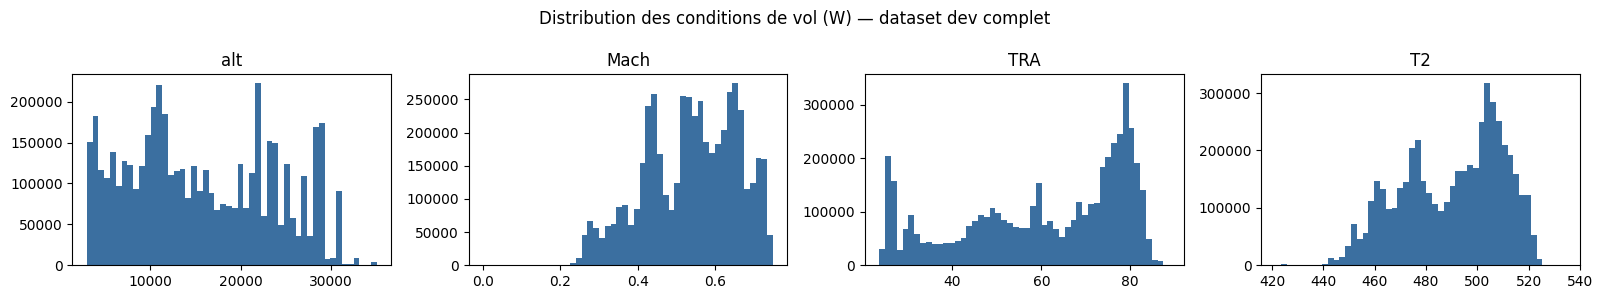

In [6]:
fig, axes = plt.subplots(1, len(flight_condition_cols), figsize=(16, 3))
for ax, col in zip(axes, flight_condition_cols):
    ax.hist(df[col], bins=50, color="#3b6fa0")
    ax.set_title(col)
fig.suptitle("Distribution des conditions de vol (W) — dataset dev complet")
fig.tight_layout()
plt.show()

## 5. Dérive des capteurs avant panne

Pour un moteur donné, on agrège au niveau cycle (`aggregate_to_cycles`, même fonction que la Phase 3) et on trace un capteur de température (`T50`, sortie basse pression) contre la RUL décroissante. Une dégradation physiquement cohérente doit montrer une dérive du capteur à mesure que la RUL approche de 0.

cycles shape: (553, 77)


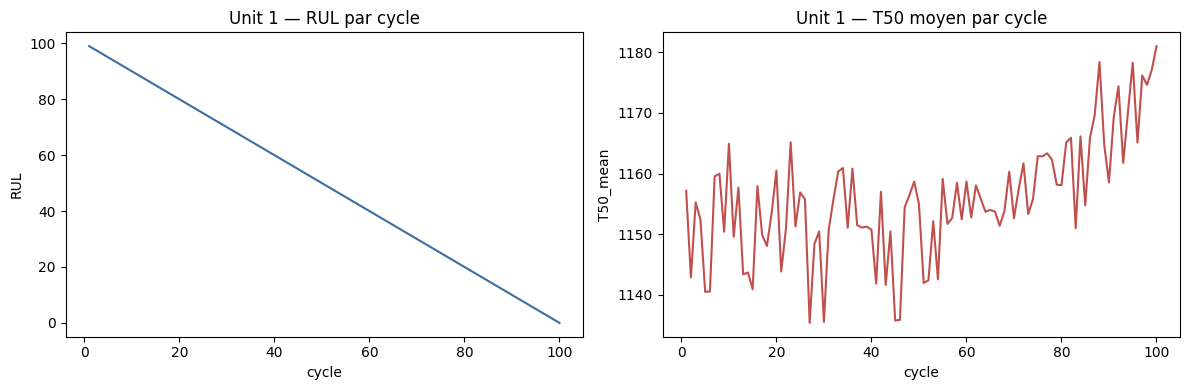

In [7]:
cycles = aggregate_to_cycles(df)
print("cycles shape:", cycles.shape)

unit_id = int(cycles["unit"].iloc[0])
one_unit = cycles[cycles["unit"] == unit_id].sort_values("cycle")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(one_unit["cycle"], one_unit["RUL"], color="#3b6fa0")
axes[0].set_title(f"Unit {unit_id} — RUL par cycle")
axes[0].set_xlabel("cycle")
axes[0].set_ylabel("RUL")

axes[1].plot(one_unit["cycle"], one_unit["T50_mean"], color="#c0504d")
axes[1].set_title(f"Unit {unit_id} — T50 moyen par cycle")
axes[1].set_xlabel("cycle")
axes[1].set_ylabel("T50_mean")

fig.tight_layout()
plt.show()

## 6. Colonnes constantes

Même logique que `src/transform.drop_constant_columns` (testée dans `tests/test_transform.py`) : au niveau cycle, sur ce dataset DS01 complet, aucune colonne agrégée ne s'avère constante — chaque statistique (`_mean/_std/_min/_max`) varie au moins un peu d'un cycle à l'autre. C'est cohérent avec la Phase 3 (`docs/phase3_etl.md`), où l'étape `drop_constant_columns` tourne sur les vraies données sans rien supprimer sur DS01.

In [8]:
non_agg_cols = {"unit", "cycle", "Fc", "hs", "RUL"}
nunique = cycles.drop(columns=[c for c in non_agg_cols if c in cycles.columns]).nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
print(f"{len(constant_cols)} colonne(s) constante(s) sur {len(nunique)} colonnes agrégées :", constant_cols)

after_drop = drop_constant_columns(cycles)
print("shape avant/après drop_constant_columns:", cycles.shape, "->", after_drop.shape)

0 colonne(s) constante(s) sur 72 colonnes agrégées : []
shape avant/après drop_constant_columns: (553, 77) -> (553, 77)


## Conclusion

- **Blocs utiles au pipeline** : `A` (identité), `W` (conditions de vol, features ML), `X_s` (capteurs physiques, features ML), `Y` (cible RUL).
- **Blocs exclus** : `X_v` (capteurs virtuels, dérivés du simulateur) et `T` (paramètres de dégradation, data leakage direct sur la cible).
- **Volume** : ~4.9M lignes 1 Hz dev → ~550 cycles après agrégation `(unit, cycle)` sur 6 moteurs — justifie l'agrégation précoce de la Phase 3.
- **Colonnes constantes** : aucune au niveau cycle sur DS01 — `drop_constant_columns` reste utile comme garde-fou générique (utile sur d'autres splits DS0x), mais n'a rien à retirer ici.
- **Dégradation physique cohérente** : la dérive de `T50` en fonction de la RUL confirme que N-CMAPSS convient mieux que FD001 (synthétique, sans dérive physique réaliste) pour la Phase 4 (ML).

**Suite** : le code de production correspondant à cette exploration vit dans [`src/extract.py`](../../src/extract.py), [`src/transform.py`](../../src/transform.py) et [`src/pipeline.py`](../../src/pipeline.py), testé dans `tests/test_phase3_etl.py` et `tests/test_transform.py`, documenté dans [`docs/phase3_etl.md`](../../docs/phase3_etl.md).